In [1]:
from pathlib import Path
import sys
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

KAGGLE_INPUT = Path("/kaggle/input")


def find_unique_file(filename):
    matches = list(KAGGLE_INPUT.rglob(filename))
    if len(matches) != 1:
        paths = "\n".join(str(path) for path in matches) or "(không tìm thấy)"
        raise FileNotFoundError(
            f"Cần tìm thấy đúng 1 file '{filename}', nhưng tìm thấy "
            f"{len(matches)}:\n{paths}"
        )
    return matches[0]


DATA_UTILS = find_unique_file("data_utils.py")
PROJECT_DIR = DATA_UTILS.parent
IMG_CSV = find_unique_file("fer2013.csv")
LABEL_CSV = find_unique_file("fer2013new.csv")

sys.path.insert(0, str(PROJECT_DIR))

print("Thư mục mã nguồn:", PROJECT_DIR)
print("File ảnh:", IMG_CSV)
print("File nhãn:", LABEL_CSV)

from data_utils import load_fer2013_csv
from dataset import FER2013Dataset
from models import CustomCNN
from eval_utils import (
    compute_epoch_metrics,
    plot_learning_curves,
    denormalize_image,
    ten_crop_inference,
    generate_gradcam,
    evaluate_private_test,
)

(
    (X_train, y_train_soft, y_train_hard),
    (X_val, y_val_soft, y_val_hard),
    (X_test, y_test_soft, y_test_hard),
) = load_fer2013_csv(
    IMG_CSV,
    LABEL_CSV,
    return_soft_labels=True,
)

print(f"Train:      {len(X_train):,} ảnh")
print(f"Validation: {len(X_val):,} ảnh")
print(f"Test:       {len(X_test):,} ảnh")
print(f"Tổng cộng:  {len(X_train) + len(X_val) + len(X_test):,} ảnh")

Thư mục mã nguồn: /kaggle/input/datasets/alceanh19/modelfer/New CNN
File ảnh: /kaggle/input/datasets/alceanh19/datasetfer/fer2013.csv
File nhãn: /kaggle/input/datasets/alceanh19/fer-2013/fer2013new.csv
=== THỐNG KÊ DỮ LIỆU ĐẦU VÀO ===
Ảnh trong fer2013.csv: 35,887 dòng
Nhãn trong fer2013new.csv: 35,887 dòng
Ghép ảnh và nhãn theo thứ tự dòng (hai file không có ID chung).

=== KẾT QUẢ LỌC VÀ CHIA TẬP ===
Bỏ qua do Usage không thuộc 3 tập: 0
Bị loại vì không còn phiếu cảm xúc > 1: 179
Bị loại vì unknown/NF >= cảm xúc cao nhất: 510
Tổng ảnh được giữ trong 3 tập: 35,198
Train: 28,153 ảnh
  Nhãn đa số: Neutral=10,179, Happiness=7,507, Surprise=3,545, Sadness=3,487, Anger=2,446, Disgust=179, Fear=648, Contempt=162
Validation: 3,524 ảnh
  Nhãn đa số: Neutral=1,322, Happiness=897, Surprise=453, Sadness=405, Anger=316, Disgust=34, Fear=73, Contempt=24
Test: 3,521 ảnh
  Nhãn đa số: Neutral=1,254, Happiness=925, Surprise=438, Sadness=439, Anger=325, Disgust=22, Fear=92, Contempt=26
Train:      28,

In [4]:
import torch.nn as nn
import torchvision.models as tv_models

def build_pretrained_resnet(num_classes=8):
    # Tải kiến trúc ResNet18 đã được huấn luyện trước
    model = tv_models.resnet18(weights=tv_models.ResNet18_Weights.DEFAULT)
    
    # Sửa lớp tích chập đầu tiên để nhận ảnh xám (1 kênh màu thay vì 3 kênh RGB)
    model.conv1 = nn.Conv2d(1, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    
    # Sửa lớp phân loại cuối cùng để xuất ra đúng 8 lớp cảm xúc
    num_ftrs = model.fc.in_features
    model.fc = nn.Linear(num_ftrs, num_classes)
    
    return model

print("Đã khởi tạo xong hàm build_pretrained_resnet!")

Đã khởi tạo xong hàm build_pretrained_resnet!


In [5]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Đang huấn luyện trên thiết bị:", device)

# Chọn một trong hai model:
# model = build_pretrained_resnet(num_classes=8).to(device)
model = CustomCNN(num_classes=8).to(device)

# Loss cho nhãn mềm FER+
kl_loss = nn.KLDivLoss(reduction="batchmean")

def soft_cross_entropy_criterion(logits, soft_targets):
    log_probs = F.log_softmax(logits, dim=1)
    return kl_loss(log_probs, soft_targets)

criterion = soft_cross_entropy_criterion

# SGD + Nesterov Momentum
optimizer = optim.SGD(
    model.parameters(),
    lr=0.01,
    momentum=0.9,
    weight_decay=1e-4,
    nesterov=True,
)

# Giảm learning rate nếu Validation Accuracy không tăng sau 4 epoch
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=4,
)

Đang huấn luyện trên thiết bị: cuda


In [7]:
import numpy as np
from torch.utils.data import DataLoader, WeightedRandomSampler
from dataset import FER2013Dataset

train_dataset = FER2013Dataset(X_train, y_train_soft, is_train=True)
val_dataset = FER2013Dataset(X_val, y_val_soft, is_train=False)
test_dataset = FER2013Dataset(X_test, y_test_hard, is_train=False)

batch_size = 64

# Tăng cơ hội lấy mẫu cho các lớp ít ảnh
class_counts = np.bincount(y_train_hard)
class_weights = 1.0 / np.sqrt(class_counts)
sample_weights = class_weights[y_train_hard]

sampler = WeightedRandomSampler(
    weights=torch.DoubleTensor(sample_weights),
    num_samples=len(sample_weights),
    replacement=True,
)

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    sampler=sampler,
    drop_last=True,
)

val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

In [9]:
num_epochs = 75
best_val_acc = 0.0
patience = 15
patience_counter = 0

print("BẮT ĐẦU GIAI ĐOẠN 1: HUẤN LUYỆN CHÍNH...")

for epoch in range(num_epochs):
    # --- TRAIN ---
    model.train()
    running_loss = 0.0
    total_train_samples = 0

    for images, soft_labels in train_loader:
        images = images.to(device)
        soft_labels = soft_labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, soft_labels)
        loss.backward()
        optimizer.step()

        batch_size_now = images.size(0)
        running_loss += loss.item() * batch_size_now
        total_train_samples += batch_size_now

    epoch_train_loss = running_loss / total_train_samples

    # --- VALIDATION ---
    model.eval()
    val_correct = 0
    total_val_samples = 0

    with torch.no_grad():
        for images, soft_labels in val_loader:
            images = images.to(device)
            soft_labels = soft_labels.to(device)

            outputs = model(images)
            preds = torch.argmax(outputs, dim=1)
            true_labels = torch.argmax(soft_labels, dim=1)

            val_correct += (preds == true_labels).sum().item()
            total_val_samples += images.size(0)

    epoch_val_acc = val_correct / total_val_samples

    # Điều chỉnh tốc độ học dựa trên validation accuracy
    scheduler.step(epoch_val_acc)
    current_lr = optimizer.param_groups[0]["lr"]

    print(
        f"Epoch [{epoch + 1}/{num_epochs}] | "
        f"LR: {current_lr:.6f} | "
        f"Train Loss: {epoch_train_loss:.4f} | "
        f"Val Acc: {epoch_val_acc * 100:.2f}%"
    )

    # Lưu model tốt nhất và dừng sớm nếu validation không cải thiện
    if epoch_val_acc > best_val_acc:
        best_val_acc = epoch_val_acc
        torch.save(model.state_dict(), "best.pth")
        patience_counter = 0
        print("   -> Đã lưu best.pth!")
    else:
        patience_counter += 1
        if patience_counter >= patience:
            print(f"Dừng sớm (Early Stopping) tại Epoch {epoch + 1}!")
            break

BẮT ĐẦU GIAI ĐOẠN 1: HUẤN LUYỆN CHÍNH...
Epoch [1/75] | LR: 0.010000 | Train Loss: 0.9690 | Val Acc: 69.32%
   -> Đã lưu best.pth!
Epoch [2/75] | LR: 0.010000 | Train Loss: 0.8517 | Val Acc: 74.72%
   -> Đã lưu best.pth!
Epoch [3/75] | LR: 0.010000 | Train Loss: 0.7828 | Val Acc: 73.81%
Epoch [4/75] | LR: 0.010000 | Train Loss: 0.7332 | Val Acc: 76.82%
   -> Đã lưu best.pth!
Epoch [5/75] | LR: 0.010000 | Train Loss: 0.6940 | Val Acc: 76.28%
Epoch [6/75] | LR: 0.010000 | Train Loss: 0.6677 | Val Acc: 77.58%
   -> Đã lưu best.pth!
Epoch [7/75] | LR: 0.010000 | Train Loss: 0.6378 | Val Acc: 76.62%
Epoch [8/75] | LR: 0.010000 | Train Loss: 0.6248 | Val Acc: 78.12%
   -> Đã lưu best.pth!
Epoch [9/75] | LR: 0.010000 | Train Loss: 0.6059 | Val Acc: 78.15%
   -> Đã lưu best.pth!
Epoch [10/75] | LR: 0.010000 | Train Loss: 0.5790 | Val Acc: 79.63%
   -> Đã lưu best.pth!
Epoch [11/75] | LR: 0.010000 | Train Loss: 0.5717 | Val Acc: 78.80%
Epoch [12/75] | LR: 0.010000 | Train Loss: 0.5580 | Val Acc

BẮT ĐẦU GIAI ĐOẠN 2: FINE-TUNING VỚI COSINE ANNEALING...
FT Epoch [1/20] | Val Acc: 82.89%
FT Epoch [2/20] | Val Acc: 82.86%
FT Epoch [3/20] | Val Acc: 83.46%
FT Epoch [4/20] | Val Acc: 83.34%
FT Epoch [5/20] | Val Acc: 83.23%
FT Epoch [6/20] | Val Acc: 82.75%
FT Epoch [7/20] | Val Acc: 83.00%
FT Epoch [8/20] | Val Acc: 83.06%
FT Epoch [9/20] | Val Acc: 82.92%
FT Epoch [10/20] | Val Acc: 83.20%
FT Epoch [11/20] | Val Acc: 83.03%
FT Epoch [12/20] | Val Acc: 83.12%
FT Epoch [13/20] | Val Acc: 82.41%
FT Epoch [14/20] | Val Acc: 82.86%
FT Epoch [15/20] | Val Acc: 82.75%
FT Epoch [16/20] | Val Acc: 82.89%
FT Epoch [17/20] | Val Acc: 83.51%
FT Epoch [18/20] | Val Acc: 82.86%
FT Epoch [19/20] | Val Acc: 82.78%
FT Epoch [20/20] | Val Acc: 83.40%

--- HOÀN TẤT HUẤN LUYỆN ---

BẮT ĐẦU ĐÁNH GIÁ TRÊN TẬP TEST...
=== TỔNG HỢP CHỈ SỐ TRÊN TẬP PRIVATETEST ===
Accuracy: 82.65% | Macro F1: 69.81% | Weighted F1: 82.68%

=== BÁO CÁO KIỂM ĐỊNH CHI TIẾT (CLASSIFICATION REPORT) ===
              precision  

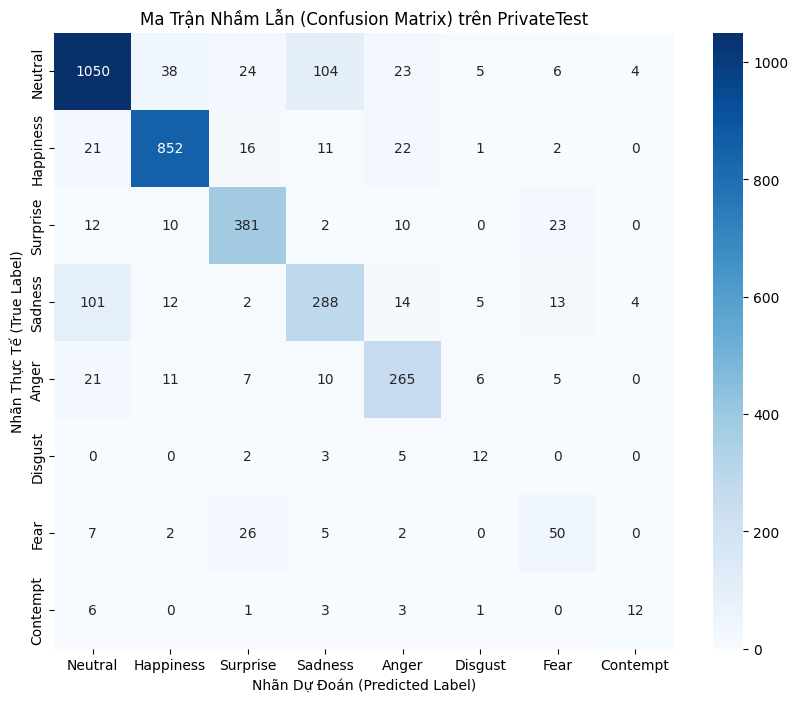

In [11]:
print("BẮT ĐẦU GIAI ĐOẠN 2: FINE-TUNING VỚI COSINE ANNEALING...")

if "best_val_acc" not in globals():
    best_val_acc = 0.0

# Nạp trọng số tốt nhất từ Giai đoạn 1
model.load_state_dict(torch.load("best.pth", map_location=device, weights_only=True))

ft_epochs = 20
optimizer_ft = optim.SGD(
    model.parameters(),
    lr=5e-4,
    momentum=0.9,
    weight_decay=1e-4,
    nesterov=True,
)
scheduler_ft = optim.lr_scheduler.CosineAnnealingLR(
    optimizer_ft,
    T_max=ft_epochs,
)

for epoch in range(ft_epochs):
    # --- TRAIN ---
    model.train()

    for images, soft_labels in train_loader:
        images = images.to(device)
        soft_labels = soft_labels.to(device)

        optimizer_ft.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, soft_labels)
        loss.backward()
        optimizer_ft.step()

    # --- VALIDATION ---
    model.eval()
    val_correct = 0
    total_val_samples = 0

    with torch.no_grad():
        for images, soft_labels in val_loader:
            images = images.to(device)
            soft_labels = soft_labels.to(device)

            outputs = model(images)
            preds = outputs.argmax(dim=1)
            true_labels = soft_labels.argmax(dim=1)

            val_correct += (preds == true_labels).sum().item()
            total_val_samples += images.size(0)

    epoch_val_acc = val_correct / total_val_samples
    scheduler_ft.step()

    if epoch_val_acc > best_val_acc:
        best_val_acc = epoch_val_acc
        torch.save(model.state_dict(), "best.pth")
        print(
            f"FT Epoch [{epoch + 1}/{ft_epochs}] | "
            f"Val Acc: {epoch_val_acc * 100:.2f}% -> Lưu best.pth mới!"
        )
    else:
        print(
            f"FT Epoch [{epoch + 1}/{ft_epochs}] | "
            f"Val Acc: {epoch_val_acc * 100:.2f}%"
        )

print("\n--- HOÀN TẤT HUẤN LUYỆN ---")

# --- ĐÁNH GIÁ TẬP TEST ---
print("\nBẮT ĐẦU ĐÁNH GIÁ TRÊN TẬP TEST...")
model.load_state_dict(torch.load("best.pth", map_location=device, weights_only=True))
model.eval()

emotion_dict = {
    0: "Neutral",
    1: "Happiness",
    2: "Surprise",
    3: "Sadness",
    4: "Anger",
    5: "Disgust",
    6: "Fear",
    7: "Contempt",
}

y_true = []
y_pred = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)
        preds = outputs.argmax(dim=1)

        # test_loader dùng nhãn cứng, nên labels có dạng [batch]
        y_true.extend(labels.cpu().numpy())
        y_pred.extend(preds.cpu().numpy())

evaluate_private_test(y_true, y_pred, emotion_dict)

BẮT ĐẦU GIAI ĐOẠN 3: KIỂM ĐỊNH TRÊN TẬP PRIVATETEST BẰNG TEN-CROP...
=== TỔNG HỢP CHỈ SỐ TRÊN TẬP PRIVATETEST ===
Accuracy: 82.96% | Macro F1: 68.88% | Weighted F1: 82.92%

=== BÁO CÁO KIỂM ĐỊNH CHI TIẾT (CLASSIFICATION REPORT) ===
              precision    recall  f1-score   support

     Neutral     0.8557    0.8509    0.8533      1254
   Happiness     0.9304    0.9254    0.9279       925
    Surprise     0.8277    0.8447    0.8362       438
     Sadness     0.6921    0.6606    0.6760       439
       Anger     0.7686    0.8277    0.7970       325
     Disgust     0.4000    0.4545    0.4255        22
        Fear     0.5052    0.5326    0.5185        92
    Contempt     0.6250    0.3846    0.4762        26

    accuracy                         0.8296      3521
   macro avg     0.7006    0.6851    0.6888      3521
weighted avg     0.8297    0.8296    0.8292      3521



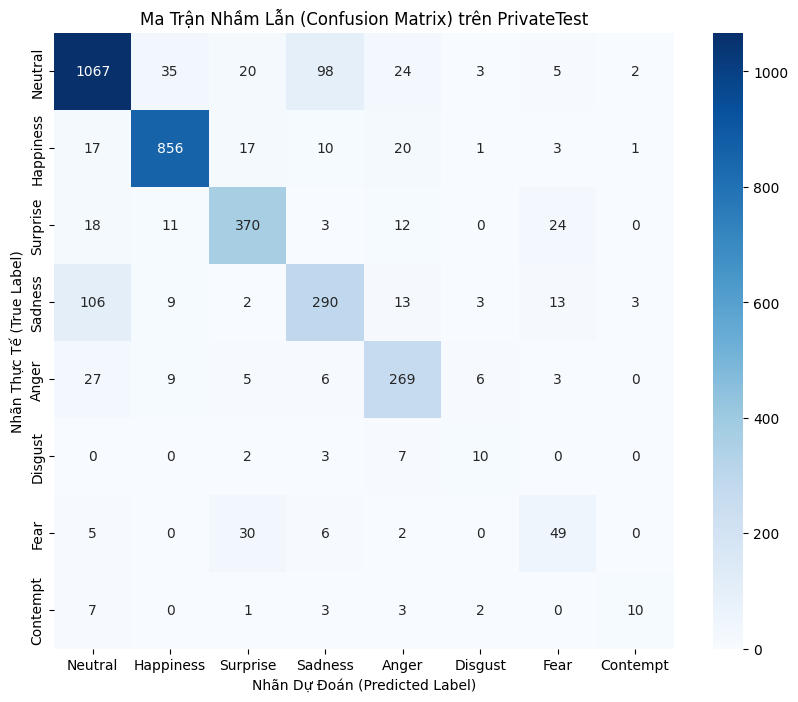

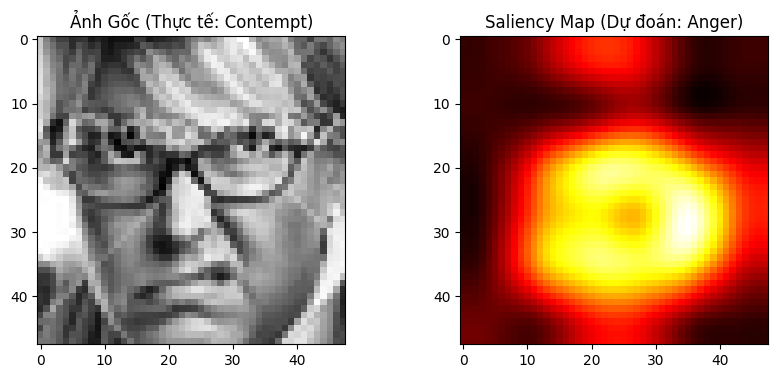

In [13]:
print("BẮT ĐẦU GIAI ĐOẠN 3: KIỂM ĐỊNH TRÊN TẬP PRIVATETEST BẰNG TEN-CROP...")
import matplotlib.pyplot as plt
# 1. Nạp file trọng số cuối cùng (Sửa thành 'best_model_custom.pth' nếu bạn đã đổi tên file ở bước trước)
model.load_state_dict(torch.load('best.pth', weights_only=True))
model.eval()

y_true = []
y_pred = []

# 2. Chạy Ten-Crop Averaging (Lưu ý: Mất nhiều thời gian hơn một chút vì 1 ảnh thành 10 ảnh)
for images, labels in test_loader:
    for i in range(images.size(0)):
        img_tensor = images[i]
        true_label = labels[i].item()
        
        # Gọi hàm từ eval_utils.py
        pred_label, _ = ten_crop_inference(model, img_tensor)
        
        y_true.append(true_label)
        y_pred.append(pred_label)

# 3. Xuất Báo cáo và Ma trận nhầm lẫn (Đã cập nhật chuẩn 8 lớp của FER+)
emotion_dict = {
    0: 'Neutral', 
    1: 'Happiness', 
    2: 'Surprise', 
    3: 'Sadness', 
    4: 'Anger', 
    5: 'Disgust', 
    6: 'Fear', 
    7: 'Contempt'
}
evaluate_private_test(y_true, y_pred, emotion_dict)

# 4. Trực quan hóa Saliency Map cho 1 ảnh Test bất kỳ
sample_img = test_dataset[0][0] # Lấy ảnh đầu tiên của tập Test
sample_label = test_dataset[0][1].item()

saliency, pred_class = generate_gradcam(model, sample_img)

# Vẽ đồ thị Saliency
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.imshow(sample_img.squeeze().numpy(), cmap='gray')
plt.title(f"Ảnh Gốc (Thực tế: {emotion_dict[sample_label]})")

plt.subplot(1, 2, 2)
plt.imshow(saliency, cmap='hot')
plt.title(f"Saliency Map (Dự đoán: {emotion_dict[pred_class]})")
plt.show()